In [6]:

from pathlib import Path
import csv

file_path = Path('data/crypto_data_SQL.csv')

with open(file_path , 'r') as csvFile:
  csvReader = csv.reader(csvFile ,delimiter = ',' )
  csv_header = next(csvReader)

print(csv_header)

['cryptocurrency', 'data_price', 'data_date', 'data_time']


In [7]:
import sqlite3


In [8]:


for field in csv_header:
  print(field)

connection = sqlite3.connect('crypto.db')
print("Database Created Successfully",connection)

connection.execute(f"CREATE TABLE IF NOT EXISTS crypto_table({csv_header[0]} string , {csv_header[1]} integer)")

connection.close()

cryptocurrency
data_price
data_date
data_time
Database Created Successfully <sqlite3.Connection object at 0x7bd4af599440>


In [14]:


connection = sqlite3.connect('crypto.db')
print("Database Created Successfully",connection)

cryptocurrency = csv_header[0]
data_price = csv_header[1]

connection.execute(f"CREATE TABLE IF NOT EXISTS crypto_table({cryptocurrency} string , {data_price} integer)")

connection.close()

Database Created Successfully <sqlite3.Connection object at 0x7bd480ba9c40>


In [11]:

cryptocurrency_list = []
data_price_list = []

from pathlib import Path
import csv

file_path = Path('data/crypto_data_SQL.csv')

with open(file_path , 'r') as csvFile:
  csvReader = csv.reader(csvFile ,delimiter = ',' )
  csv_header = next(csvReader)
  for row in csvReader:
    cryptocurrency_list.append(row[0])
    data_price_list.append(row[1])

connection = sqlite3.connect('crypto.db')
print("Database Created Successfully",connection)

counter = int(len(cryptocurrency_list))

for i in range (counter):
  # Adding one data
  # connection.execute(f'INSERT INTO crypto_table VALUES({cryptocurrency_list[i]}text);')
  connection.execute("INSERT INTO crypto_table (cryptocurrency, data_price) VALUES (?, ?)",(cryptocurrency_list[i], data_price_list[i]))
connection.commit()
connection.close()

Database Created Successfully <sqlite3.Connection object at 0x7bd4af599340>


In [12]:
connection = sqlite3.connect('crypto.db')
print("Database Created Successfully",connection)

data = connection.execute('''SELECT * FROM crypto_table''')


for z in data:
  print(z)


connection.close()

Database Created Successfully <sqlite3.Connection object at 0x7bd4af599640>
('bitcoin', '')
('bitcoin', 1743.723523)
('bitcoin', 1828.678209)
('bitcoin', 1776.443919)
('bitcoin', 1714.964198)
('bitcoin', 1789.278913)
('bitcoin', 1742.722945)
('bitcoin', '')
('bitcoin', 1802.035054)
('bitcoin', 1840.501678)
('bitcoin', 1932.284978)
('bitcoin', 1988.961436)
('bitcoin', 2041.043206)
('bitcoin', 2132.615875)
('bitcoin', 2192.000968)
('bitcoin', '')
('bitcoin', 2545.894708)
('bitcoin', 2372.674114)
('bitcoin', 2046.891968)
('bitcoin', 2155.227076)
('bitcoin', 2212.049849)
('bitcoin', 2250.859259)
('bitcoin', '')
('bitcoin', 2372.288414)
('bitcoin', 2407.755441)
('bitcoin', 2500.43098)
('bitcoin', 2505.279935)
('bitcoin', 2588.95147)
('bitcoin', 2819.741341)
('bitcoin', 2807.993735)
('bitcoin', 2746.115898)
('bitcoin', 2817.290994)
('bitcoin', 2846.735247)
('bitcoin', 2894.776615)
('bitcoin', 2782.433486)
('bitcoin', 2697.921409)
('bitcoin', 2644.42532)
('bitcoin', 2357.075417)
('bitcoin', 2

Database Created Successfully <sqlite3.Connection object at 0x7bd480ba8b40>


TypeError: 'value' must be an instance of str or bytes, not a float

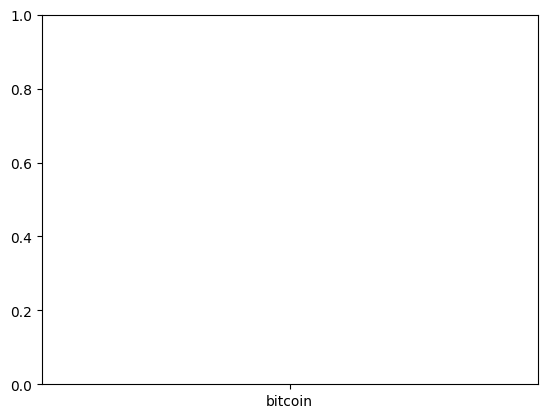

In [13]:
import matplotlib.pyplot as plt
import pandas as pd


connection = sqlite3.connect('crypto.db')
print("Database Created Successfully",connection)

crypto_name_cursor = connection.execute('''SELECT cryptocurrency FROM crypto_table''')
crypto_price_cursor = connection.execute('''SELECT data_price FROM crypto_table''')

crypto_name_list = []
crypto_price_list = []


for r in crypto_name_cursor:
  crypto_name_list.append(str(r[0]))

for r in crypto_price_cursor:
  crypto_price_list.append(r[0])

plt.bar(crypto_name_list,crypto_price_list,color ='red')


connection.close()